<a href="https://colab.research.google.com/github/fellahinourelhouda/Anemia/blob/main/Nour_M2_nutrition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# Chemin du fichier
file_path = '/content/Nour Anemia M2.xlsx'

# Lire le fichier Excel pour obtenir les noms des feuilles
excel_file = pd.ExcelFile(file_path)
print("Feuilles disponibles dans le fichier :", excel_file.sheet_names)

# Charger la première feuille par défaut
df = pd.read_excel(file_path, sheet_name=0)

# Afficher un aperçu des données
display(df.head())

Feuilles disponibles dans le fichier : ['Sheet1']


,Gender,Age,Hb,RBC,PCV,MCV,MCH,MCHC,Decision_Class
0,f,32,10.9,4.26,34.2,80.2,25.5,31.8,1
1,f,45,9.6,3.64,29.9,82.1,26.4,32.2,1
2,f,38,10.1,3.70,32.4,87.6,27.4,31.3,1
3,m,37,11.0,3.93,33.6,85.3,27.9,32.7,1
4,f,50,12.1,4.16,36.5,87.9,29.2,33.2,0


In [3]:
import pandas as pd

# Afficher les informations générales sur les colonnes et types de données
print("--- Informations sur le Dataset ---")
df.info()

# Afficher un résumé des statistiques descriptives pour les variables numériques
print("\n--- Statistiques Descriptives (Numériques) ---")
display(df.describe(include='all'))

# Vérifier le nombre de valeurs manquantes par colonne
print("\n--- Valeurs Manquantes par Colonne ---")
print(df.isnull().sum())

--- Informations sur le Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          1000 non-null   object 
 1   Age             1000 non-null   int64  
 2   Hb              1000 non-null   float64
 3   RBC             1000 non-null   float64
 4   PCV             1000 non-null   float64
 5   MCV             1000 non-null   float64
 6   MCH             1000 non-null   float64
 7   MCHC            1000 non-null   float64
 8   Decision_Class  1000 non-null   int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 70.4+ KB

--- Statistiques Descriptives (Numériques) ---


,Gender,Age,Hb,RBC,PCV,MCV,MCH,MCHC,Decision_Class
count,1000,1000.000000,1000.000000,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000,1000.000000
unique,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,672,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,40.956000,11.568400,4.133810,32.65240,79.22000,28.143400,35.427000,0.641000
std,NaN,16.019322,1.336715,0.599695,4.85723,7.77521,3.340107,1.418162,0.479947
min,NaN,18.000000,5.500000,1.470000,10.60000,29.60000,13.300000,25.300000,0.000000
25%,NaN,28.000000,10.800000,3.767500,29.80000,75.20000,26.400000,34.900000,0.000000
50%,NaN,38.000000,11.600000,4.110000,32.80000,80.70000,28.700000,35.700000,1.000000
75%,NaN,51.250000,12.200000,4.460000,35.62500,84.42500,30.400000,36.300000,1.000000



--- Valeurs Manquantes par Colonne ---
Gender            0
Age               0
Hb                0
RBC               0
PCV               0
MCV               0
MCH               0
MCHC              0
Decision_Class    0
dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. Encodage de la variable qualitative 'Gender' (f -> 0, m -> 1 par exemple)
df_prep = df.copy()
df_prep['Gender'] = df_prep['Gender'].map({'f': 0, 'm': 1})

# 2. Définition de X et Y
X = df_prep.drop(columns=['Decision_Class'])
y = df_prep['Decision_Class']

# 3. Séparation en données d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Données préparées avec succès !")
print(f"Taille de X_train : {X_train.shape}")
print(f"Taille de X_test : {X_test.shape}")

Données préparées avec succès !
Taille de X_train : (800, 8)
Taille de X_test : (200, 8)


Exactitude globale (Accuracy) : 100.00%

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        72
           1       1.00      1.00      1.00       128

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



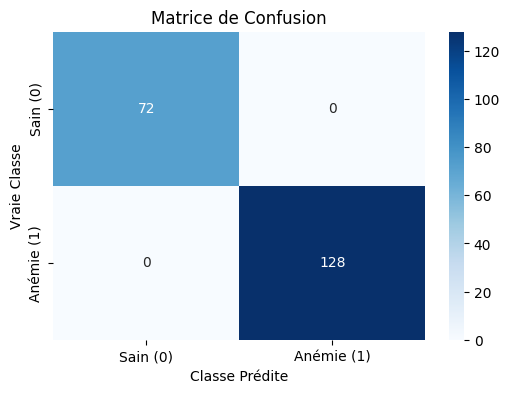

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Initialisation et entraînement du modèle Random Forest
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train, y_train)

# 2. Prédictions sur l'ensemble de test
y_pred = model.predict(X_test)

# 3. Évaluation du modèle
accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitude globale (Accuracy) : {accuracy:.2%}\n")

print("Rapport de classification :")
print(classification_report(y_test, y_pred))

# Affichage de la matrice de confusion
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sain (0)', 'Anémie (1)'], yticklabels=['Sain (0)', 'Anémie (1)'])
plt.title('Matrice de Confusion')
plt.ylabel('Vraie Classe')
plt.xlabel('Classe Prédite')
plt.show()

In [7]:
# 1. Affichage des dimensions
print("=== Dimensions des données ===")
print(f"Dimensions de X (caractéristiques) : {X.shape} (lignes, colonnes)")
print(f"Dimensions de Y (cible)            : {y.shape} (éléments)")
print(f"Nombre total d'individus           : {len(df_prep)}")

# 2. Aperçu des données
print("\n=== Aperçu de X (premières lignes) ===")
display(X.head())

print("\n=== Aperçu de Y (premières lignes) ===")
display(y.head().to_frame())

=== Dimensions des données ===
Dimensions de X (caractéristiques) : (1000, 8) (lignes, colonnes)
Dimensions de Y (cible)            : (1000,) (éléments)
Nombre total d'individus           : 1000

=== Aperçu de X (premières lignes) ===


,Gender,Age,Hb,RBC,PCV,MCV,MCH,MCHC
0,0,32,10.9,4.26,34.2,80.2,25.5,31.8
1,0,45,9.6,3.64,29.9,82.1,26.4,32.2
2,0,38,10.1,3.70,32.4,87.6,27.4,31.3
3,1,37,11.0,3.93,33.6,85.3,27.9,32.7
4,0,50,12.1,4.16,36.5,87.9,29.2,33.2



=== Aperçu de Y (premières lignes) ===


,Decision_Class
0,1
1,1
2,1
3,1
4,0


In [8]:
# Répartition des données avec 75% entraînement et 25% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Affichage du nombre d'individus dans chaque ensemble
print("=== Nouvelle répartition des données (75% / 25%) ===")
print(f"Nombre d'individus dans l'ensemble d'entraînement (Train) : {X_train.shape[0]} patients")
print(f"Nombre d'individus dans l'ensemble de test (Test)          : {X_test.shape[0]} patients")

=== Nouvelle répartition des données (75% / 25%) ===
Nombre d'individus dans l'ensemble d'entraînement (Train) : 750 patients
Nombre d'individus dans l'ensemble de test (Test)          : 250 patients


=== Évaluation Statistique Globale ===
Exactitude (Accuracy) : 1.0000 (Indique la proportion globale de prédictions correctes)
Aire sous la courbe ROC (ROC-AUC) : 1.0000 (Mesure la capacité de discrimination du modèle)

=== Rapport de Classification Standardisé ===
              precision    recall  f1-score   support

    Sain (0)     1.0000    1.0000    1.0000        90
Anémique (1)     1.0000    1.0000    1.0000       160

    accuracy                         1.0000       250
   macro avg     1.0000    1.0000    1.0000       250
weighted avg     1.0000    1.0000    1.0000       250



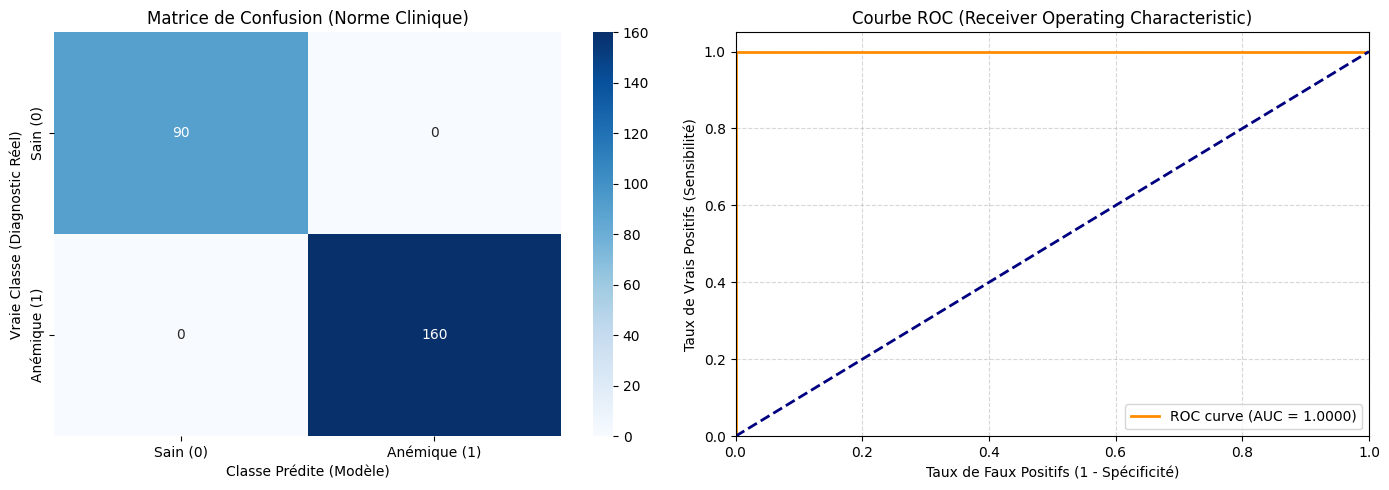

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Entraînement du modèle Random Forest sur la nouvelle répartition (75% / 25%)
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)

# 2. Prédictions et probabilités
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

# 3. Calcul des métriques globales
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=== Évaluation Statistique Globale ===")
print(f"Exactitude (Accuracy) : {accuracy:.4f} (Indique la proportion globale de prédictions correctes)")
print(f"Aire sous la courbe ROC (ROC-AUC) : {roc_auc:.4f} (Mesure la capacité de discrimination du modèle)")

# 4. Rapport de classification détaillé
print("\n=== Rapport de Classification Standardisé ===")
print(classification_report(y_test, y_pred, target_names=['Sain (0)', 'Anémique (1)'], digits=4))

# 5. Visualisations : Matrice de confusion et Courbe ROC
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sain (0)', 'Anémique (1)'],
            yticklabels=['Sain (0)', 'Anémique (1)'], ax=ax[0])
ax[0].set_title('Matrice de Confusion (Norme Clinique)')
ax[0].set_ylabel('Vraie Classe (Diagnostic Réel)')
ax[0].set_xlabel('Classe Prédite (Modèle)')

# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('Taux de Faux Positifs (1 - Spécificité)')
ax[1].set_ylabel('Taux de Vrais Positifs (Sensibilité)')
ax[1].set_title('Courbe ROC (Receiver Operating Characteristic)')
ax[1].legend(loc="lower right")
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Décryptage Clinique et Statistique des Métriques d'Évaluation

Pour valider scientifiquement notre modèle d'identification de l'anémie, nous analysons ses résultats à travers plusieurs indicateurs clés :

#### 1. La Matrice de Confusion (Interprétation clinique)
* **Vrais Négatifs (VN) :** Patients sains correctement identifiés comme sains par le modèle.
* **Vrais Positifs (VP) :** Patients anémiques correctement diagnostiqués comme anémiques.
* **Faux Positifs (FP) - *Erreur de Type I* :** Patients sains qualifiés à tort d'anémiques par le modèle. Cliniquement, cela entraîne des examens complémentaires inutiles et du stress pour le patient.
* **Faux Négatifs (FN) - *Erreur de Type II* :** Patients anémiques non détectés par le modèle. **C'est l'erreur la plus critique en médecine**, car un patient malade reste sans traitement.

#### 2. Les Métriques Standardisées (Rapport de classification)
* **La Sensibilité (Recall / Rappel) :** $\frac{VP}{VP + FN}$. Elle mesure la capacité du modèle à détecter tous les malades. Un rappel de 100% signifie qu'aucun malade n'a été manqué.
* **La Précision :** $\frac{VP}{VP + FP}$. Elle mesure la fiabilité d'un diagnostic positif. Une précision de 100% signifie que chaque fois que le modèle prédit l'anémie, le patient l'est réellement.
* **L'Exactitude (Accuracy) :** $\frac{VP+VN}{\text{Total}}$. La proportion globale de diagnostics corrects. Attention, elle peut être trompeuse si le jeu de données est très déséquilibré.
* **Le F1-Score :** Moyenne harmonique de la précision et du rappel. C'est l'indicateur de performance globale le plus robuste pour valider le modèle.

#### 3. La Courbe ROC et l'AUC
* L'**AUC (Area Under the Curve)** varie entre 0.5 (modèle aléatoire) et 1.0 (modèle parfait).
* En médecine, un score AUC > 0.90 est considéré comme **excellent**. Il démontre que le modèle sépare de manière optimale les distributions de mesures biologiques des patients sains et anémiques.

### Pourquoi cette répartition (75% / 25%) ?

* **L'ensemble d'entraînement (75 % - 750 individus) :**
  Il fournit la majorité des données au modèle pour qu'il apprenne les relations et motifs biologiques (comme le lien entre un faible taux d'hémoglobine ou de globules rouges et le diagnostic de l'anémie).

* **L'ensemble de test (25 % - 250 individus) :**
  Il sert de « groupe de contrôle » avec des données que le modèle n'a jamais vues durant sa phase d'apprentissage. Cela permet d'évaluer de manière totalement objective et impartiale l'efficacité et la capacité de généralisation du modèle sur de nouveaux patients.

* **La stratification (`stratify=y`) :**
  Nous conservons la même proportion de cas sains et d'anémiques dans les deux ensembles, ce qui évite de fausser les résultats lors de l'évaluation.

### Analyse Détaillée des Variables du Dataset

Dans le cadre d'un modèle de **Machine Learning Supervisé**, nous divisons les données en deux catégories : les variables caractéristiques ($X$) et la variable cible ($Y$).

---

#### 1. La Variable Cible : $Y$
La variable cible est ce que le modèle cherche à prédire.

* **`Decision_Class`** (Type : `int64`, Valeurs : `0` ou `1`)
  * **Signification** : C'est le diagnostic médical final.
  * **Interprétation** :
    * `1` : Présence d'anémie.
    * `0` : Absence d'anémie (Sujet sain).
  * **Rôle** : C'est une tâche de **classification binaire**.

---

#### 2. Les Variables Explicatives : $X$
Ces variables sont les caractéristiques (features) biologiques et démographiques utilisées par le modèle pour apprendre à prédire $Y$.

##### Données démographiques :
* **`Gender`** (Sexe - Type : `object` / converti en `int`)
  * **Signification** : Le sexe du patient (`f` pour femme, `m` pour homme).
  * **Importance** : Les seuils de diagnostic de l'anémie (notamment pour l'hémoglobine) diffèrent physiologiquement entre les hommes et les femmes.
* **`Age`** (Âge - Type : `int64`)
  * **Signification** : L'âge du patient en années.
  * **Importance** : L'âge influence la production de globules rouges et les besoins en fer de l'organisme.

##### Paramètres de l'Hémogramme (NFS - Numération Formule Sanguine) :
* **`Hb`** (Hémoglobine - Type : `float64`)
  * **Signification** : La concentration d'hémoglobine dans le sang.
  * **Importance** : C'est le critère principal pour définir l'anémie (un taux bas d'hémoglobine caractérise directement l'anémie).
* **`RBC`** (Red Blood Cells / Globules Rouges - Type : `float64`)
  * **Signification** : Le nombre total de globules rouges par microlitre de sang.
  * **Importance** : Une diminution de ce nombre réduit la capacité de transport de l'oxygène.
* **`PCV`** (Packed Cell Volume / Hématocrite - Type : `float64`)
  * **Signification** : Le pourcentage du volume total de sang occupé par les globules rouges.
  * **Importance** : Très lié au taux de globules rouges et d'hémoglobine, un PCV bas est un indicateur fort d'anémie.
* **`MCV`** (Mean Corpuscular Volume / VGM - Type : `float64`)
  * **Signification** : Le volume moyen d'un globule rouge.
  * **Importance** : Permet de classifier l'anémie : microcytaire (petits globules, MCV < 80, souvent par carence en fer) ou macrocytaire (gros globules, MCV > 100).
* **`MCH`** (Mean Corpuscular Hemoglobin / TCMH - Type : `float64`)
  * **Signification** : La quantité moyenne d'hémoglobine contenue dans un globule rouge.
  * **Importance** : Liée à la couleur des globules (anémie hypochrome ou normochrome).
* **`MCHC`** (Mean Corpuscular Hemoglobin Concentration / CCMH - Type : `float64`)
  * **Signification** : La concentration moyenne d'hémoglobine dans un volume donné de globules rouges.
  * **Importance** : Complète les indices précédents pour caractériser la saturation en hémoglobine.